In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

from scipy.special import iv, kv, ive, kve

from prodpy.transient import InfiniteActing

In [2]:
def arps_rate_ratio(t, b, *, check_input=True):
    """
    Calculate the Arps dimensionless rate ratio q/q_i.

    The Arps decline equation is:

        q / q_i = 1 / (1 + b * t) ** (1 / b)

    where t is dimensionless decline time:

        t = D_i * time

    Special cases:
        b = 0  -> exponential decline
        b = 1  -> harmonic decline

    Parameters
    ----------
    t : float or array-like
        Dimensionless decline time, usually D_i * time.
        Must be non-negative.
    b : float
        Arps decline exponent.
        Common range is 0 <= b <= 1.
    check_input : bool, default True
        If True, checks for negative time and invalid b.

    Returns
    -------
    float or np.ndarray
        Dimensionless rate ratio q/q_i.

    Examples
    --------
    >>> arps_rate_ratio(0, b=0.5)
    1.0

    >>> arps_rate_ratio([0, 1, 2], b=0)
    array([1.        , 0.36787944, 0.13533528])

    >>> arps_rate_ratio([0, 1, 2], b=1)
    array([1.        , 0.5       , 0.33333333])
    """
    t = np.asarray(t, dtype=float)

    if check_input:
        if np.any(t < 0):
            raise ValueError("Time values must be non-negative.")

        if not np.isfinite(b):
            raise ValueError("b must be a finite number.")

        if b < 0:
            raise ValueError("b must be non-negative for standard Arps decline.")

    if np.isclose(b, 0.0):
        q_ratio = np.exp(-t)

    elif np.isclose(b, 1.0):
        q_ratio = 1.0 / (1.0 + t)

    else:
        # More numerically stable than:
        # 1 / np.power(1 + b * t, 1 / b)
        q_ratio = np.exp(-np.log1p(b * t) / b)

    if q_ratio.ndim == 0:
        return float(q_ratio)

    return q_ratio

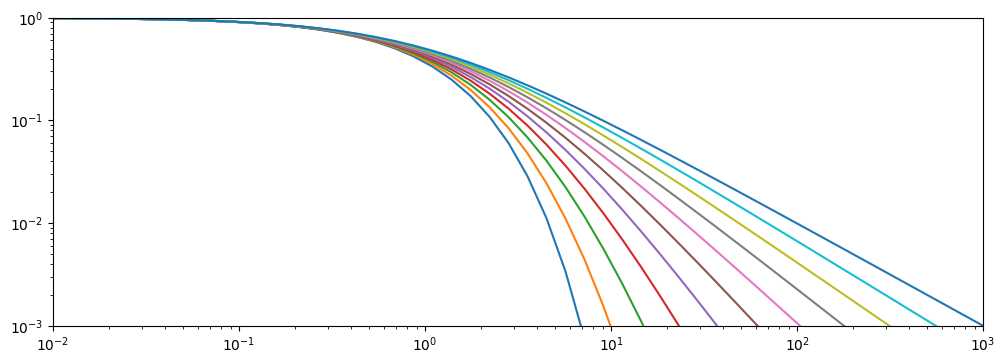

In [3]:
t = np.logspace(-2,3)

plt.figure(figsize=(12,4))

for b in np.arange(0,1.01,0.1):
    plt.loglog(t,arps_rate_ratio(t,b))

plt.ylim(bottom=0.001,top=1)
plt.xlim((1e-2,1e3))

plt.show()

In [32]:
tD = np.logspace(4,9)

# def pss(tD,reD):
#     term = 1/(np.log(reD) - 3/4)
#     return term * np.exp(-2 * tD * term / reD**2)

def pss(tD, reD):
    """
    Late-time PSS approximation expressed in qD.

    In Fetkovich Fig. 3 variables:

        qDd = exp(-tDd)

    Therefore:

        qD = exp(-tDd) / [ln(reD) - 0.5]
    """
    tD = np.asarray(tD, dtype=float)

    b = np.log(reD) - 1/2
    tDd = tD/(0.5 * (reD**2 - 1.0) * b)

    return np.exp(-tDd) / b

def radial(tD, reD):
    tD = np.asarray(tD, dtype=float)
    qD = np.empty_like(tD)

    tDAcut = 0.1
    tDcut = tDAcut * np.pi * reD**2

    early_time_flag = tD<tDcut
    early_time = tD[early_time_flag]
    late_time = tD[~early_time_flag]

    reD = np.array([reD])  # Ensure reD is array for broadcasting in get_theta

    qD[early_time_flag] = np.nan

    if late_time.size > 0:
        qD[~early_time_flag] = pss(late_time, reD)

    return qD

In [33]:
def fetkovich_time_scale(reD):
    """
    Fetkovich Fig. 3 time scaling factor.

    tDd = tD / scale

    where:

        scale = 0.5 * (reD**2 - 1) * [ln(reD) - 0.5]
    """
    reD = float(reD)

    if reD <= 1:
        raise ValueError("reD must be greater than 1.")

    b = np.log(reD) - 0.5
    scale = 0.5 * (reD**2 - 1.0) * b

    return scale


def qD_to_qDd(qD, reD):
    """
    Convert qD to Fetkovich decline dimensionless rate qDd.
    """
    return qD * (np.log(reD) - 0.5)


def tD_to_tDd(tD, reD):
    """
    Convert tD to Fetkovich decline dimensionless time tDd.
    """
    scale = fetkovich_time_scale(reD)
    return tD / scale


def tDd_to_tD(tDd, reD):
    """
    Convert Fetkovich decline dimensionless time tDd to tD.
    """
    scale = fetkovich_time_scale(reD)
    return tDd * scale


def pss_qD_fig3(tD, reD):
    """
    Late-time PSS approximation expressed in qD.

    In Fetkovich Fig. 3 variables:

        qDd = exp(-tDd)

    Therefore:

        qD = exp(-tDd) / [ln(reD) - 0.5]
    """
    tD = np.asarray(tD, dtype=float)

    b = np.log(reD) - 0.5
    tDd = tD_to_tDd(tD, reD)

    return np.exp(-tDd) / b


def radial_approx_fig3(tDd, reD, tDAcut=0.1):
    """
    Approximate Fetkovich Fig. 3 curve using:
        early time: infinite-acting solution
        late time: PSS exponential solution

    This does NOT reproduce the exact finite-boundary transition.
    It only gives a rough asymptotic approximation.
    """
    tDd = np.asarray(tDd, dtype=float)

    tD = tDd_to_tD(tDd, reD)

    qD = np.empty_like(tD)

    # Conventional PSS onset estimate
    tDcut = tDAcut * np.pi * reD**2

    early = tD < tDcut
    late = ~early

    xxx = InfiniteActing.get_theta(tD[early], np.array([1]))

    print(xxx.shape)

    qD[early] = InfiniteActing.get_theta(tD[early], np.array([1]))
    qD[late] = pss_qD_fig3(tD[late], reD)

    qDd = qD_to_qDd(qD, reD)

    return qDd

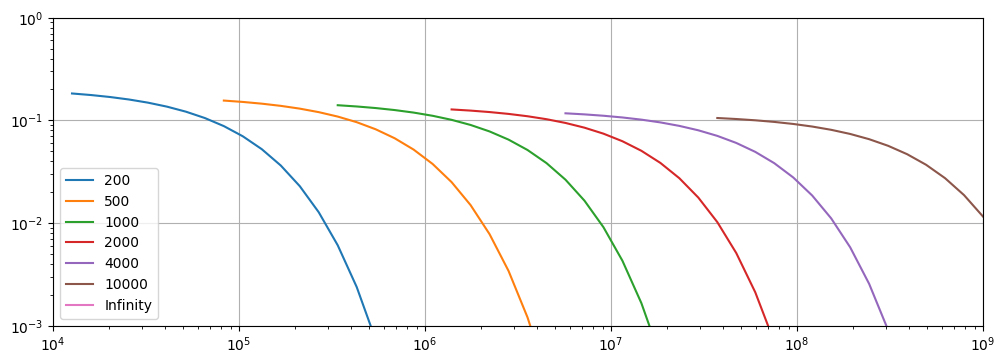

In [34]:
plt.figure(figsize=(12,4))

for r in [200,500,1000,2000,4000,10000]:
    plt.loglog(tD,radial(tD,r),label=f"{r}")

plt.loglog(tD,radial(tD, reD = np.inf),label="Infinity")

plt.ylim((0.001,1))
plt.xlim((1e4,1e9))
plt.legend()
plt.grid()

plt.show()

In [ ]:
def fetkovich_transform(tDd: np.ndarray, reD: float) -> tuple[np.ndarray, np.ndarray]:
    """
    Convert constant-pressure radial qD(tD) solution into Fetkovich decline variables.

    qDd = qD * [ln(reD) - 1/2]

    tDd = tD / {0.5 * [(reD)^2 - 1] * [ln(reD) - 1/2]}

    Therefore:

    tD = tDd * {0.5 * [(reD)^2 - 1] * [ln(reD) - 1/2]}
    """
    b = np.log(reD) - 0.5

    tD_scale = 0.5 * (reD**2 - 1.0) * b
    tD = tDd * tD_scale

    qD = qD_constant_pressure(tD, reD=reD, n_terms=12)
    qDd = qD * b

    return tDd, qDd

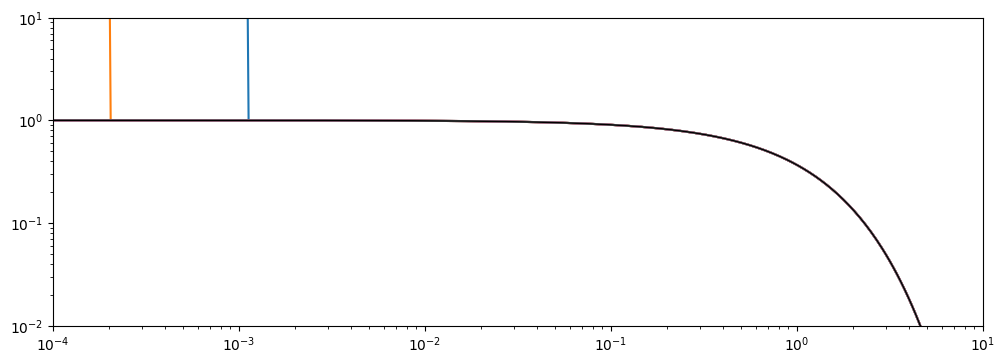

In [6]:
tDd = np.logspace(-4,1,500)

plt.figure(figsize=(12,4))

for reD in [10,20,50,100,200,1000,10000,100000]:

    tD = tDd*(0.5*(reD**2-1)*(np.log(reD)-0.5))
    qD = radial(tD,reD)

    qDd = qD*(np.log(reD)-0.5)

    plt.loglog(tDd,qDd)

q_exp = np.exp(-tDd)

plt.loglog(tDd,q_exp,linewidth = 1,color='k')

plt.ylim((0.01,10))
plt.xlim(1e-4,1e1)
plt.show()

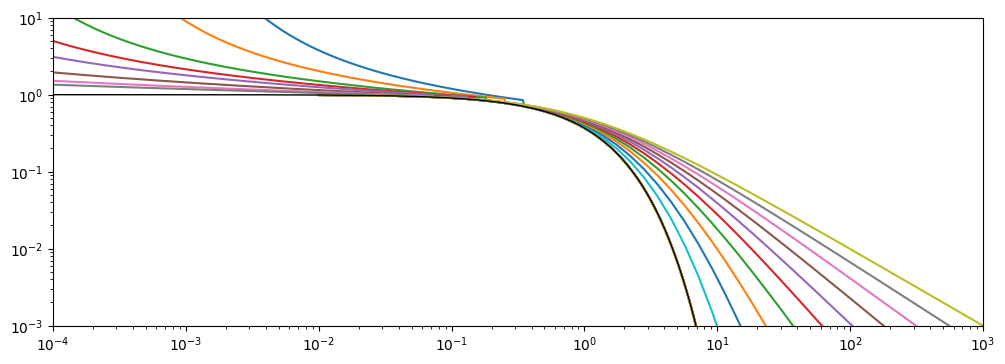

In [18]:
tDd = np.logspace(-4,1,500)

plt.figure(figsize=(12,4))

for r in [10,20,50,100,200,1000,10000,100000]:

    tD = tDd*(0.5*(r**2-1)*(np.log(r)-0.5))
    qD = radial(tD,r)

    qDd = qD*(np.log(r)-0.5)

    plt.loglog(tDd,qDd)

for b in np.arange(0,1.01,0.1):
    y = arps_rate_ratio(t,b)
    plt.loglog(t,y)


q_exp = np.exp(-tDd)

plt.loglog(tDd,q_exp,linewidth = 1,color='k')

plt.ylim(bottom=0.001,top=10)
plt.xlim(1e-4,1e3)
plt.show()

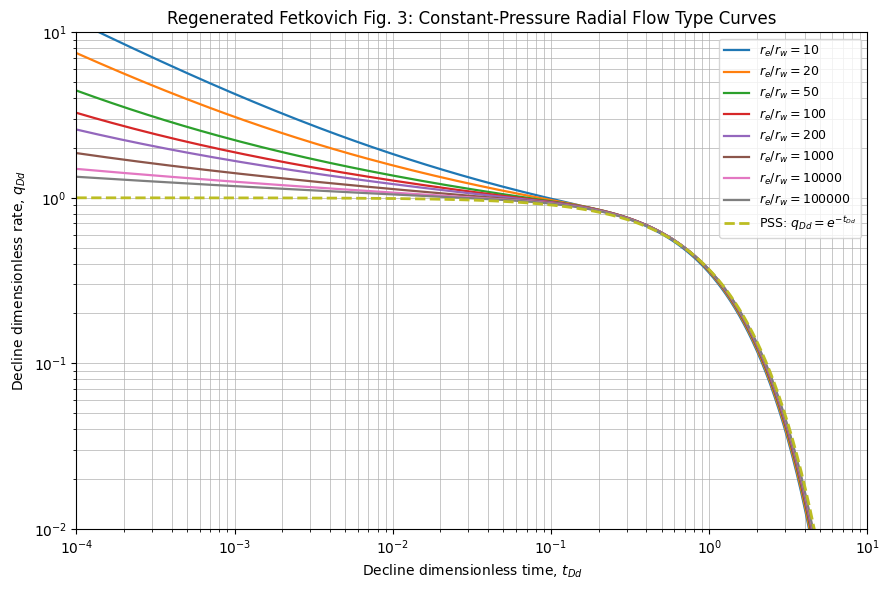

In [ ]:
def stehfest_coefficients(n_terms: int = 12) -> np.ndarray:
    """
    Compute Gaver-Stehfest coefficients for numerical inverse Laplace transform.

    Parameters
    ----------
    n_terms : int
        Number of Stehfest terms. Must be even.
        10 or 12 is usually stable for engineering type-curve work.

    Returns
    -------
    np.ndarray
        Stehfest coefficients indexed from 1 to n_terms.
    """
    if n_terms % 2 != 0:
        raise ValueError("n_terms must be even.")

    v = np.zeros(n_terms + 1)

    for k in range(1, n_terms + 1):
        summation = 0.0

        j_min = (k + 1) // 2
        j_max = min(k, n_terms // 2)

        for j in range(j_min, j_max + 1):
            numerator = (j ** (n_terms // 2)) * math.factorial(2 * j)

            denominator = (
                math.factorial(n_terms // 2 - j)
                * math.factorial(j)
                * math.factorial(j - 1)
                * math.factorial(k - j)
                * math.factorial(2 * j - k)
            )

            summation += numerator / denominator

        v[k] = ((-1) ** (k + n_terms // 2)) * summation

    return v


def k1_over_i1(z: np.ndarray) -> np.ndarray:
    """
    Stable evaluation of K1(z) / I1(z).

    For large z, direct scipy.special.kv / iv may underflow or overflow.
    Scaled Bessel functions are used for stability.
    """
    z = np.asarray(z, dtype=float)
    ratio = np.empty_like(z)

    small = z < 50.0
    large = ~small

    ratio[small] = kv(1, z[small]) / iv(1, z[small])

    # K1/I1 = [kve(1,z) exp(-z)] / [ive(1,z) exp(z)]
    #       = [kve(1,z) / ive(1,z)] exp(-2z)
    ratio[large] = (kve(1, z[large]) / ive(1, z[large])) * np.exp(-2.0 * z[large])

    return ratio


def qbar_constant_pressure_radial(s: np.ndarray, reD: float) -> np.ndarray:
    """
    Laplace-space dimensionless rate for radial flow with:
        inner boundary: constant pressure at rD = 1
        outer boundary: no-flow at rD = reD

    The solution is written in terms of modified Bessel functions.

    Parameters
    ----------
    s : array-like
        Laplace variable.
    reD : float
        Dimensionless external radius, re / rw.

    Returns
    -------
    np.ndarray
        Laplace transform of qD(tD).
    """
    s = np.asarray(s, dtype=float)
    u = np.sqrt(s)

    eta = k1_over_i1(u * reD)

    numerator = kv(1, u) - eta * iv(1, u)
    denominator = kv(0, u) + eta * iv(0, u)

    return (u / s) * (numerator / denominator)


def inverse_laplace_stehfest(func, t: np.ndarray, n_terms: int = 12, **kwargs) -> np.ndarray:
    """
    Numerical inverse Laplace transform using the Gaver-Stehfest algorithm.
    """
    t = np.asarray(t, dtype=float)
    ln2 = np.log(2.0)
    v = stehfest_coefficients(n_terms)

    result = np.zeros_like(t)

    for k in range(1, n_terms + 1):
        s = k * ln2 / t
        result += v[k] * func(s, **kwargs)

    return (ln2 / t) * result


def qD_constant_pressure(tD: np.ndarray, reD: float, n_terms: int = 12) -> np.ndarray:
    """
    Compute qD(tD) for finite radial reservoir under constant well pressure.
    """
    return inverse_laplace_stehfest(
        qbar_constant_pressure_radial,
        tD,
        n_terms=n_terms,
        reD=reD,
    )


def fetkovich_transform(tDd: np.ndarray, reD: float) -> tuple[np.ndarray, np.ndarray]:
    """
    Convert constant-pressure radial qD(tD) solution into Fetkovich decline variables.

    qDd = qD * [ln(reD) - 1/2]

    tDd = tD / {0.5 * [(reD)^2 - 1] * [ln(reD) - 1/2]}

    Therefore:

    tD = tDd * {0.5 * [(reD)^2 - 1] * [ln(reD) - 1/2]}
    """
    b = np.log(reD) - 0.5

    tD_scale = 0.5 * (reD**2 - 1.0) * b
    tD = tDd * tD_scale

    qD = qD_constant_pressure(tD, reD=reD, n_terms=12)
    qDd = qD * b

    return tDd, qDd

# Decline-curve dimensionless time range.
tDd = np.logspace(-4, 1, 180)

# Approximate radius ratios shown in Fetkovich Fig. 3.
reD_values = [10, 20, 50, 100, 200, 1_000, 10_000, 100_000]

plt.figure(figsize=(9, 6))

for reD in reD_values:
    x, y = fetkovich_transform(tDd, reD)

    plt.loglog(x, y, linewidth=1.6, label=fr"$r_e/r_w={reD:g}$")

# Long-time pseudo-steady-state exponential decline reference.
# In Fetkovich decline variables, finite-boundary solutions converge to this line.
t_exp = np.logspace(-4, 1, 180)
q_exp = np.exp(-t_exp)

plt.loglog(t_exp, q_exp, linestyle="--", linewidth=2.0, label=r"PSS: $q_{Dd}=e^{-t_{Dd}}$")

plt.xlabel(r"Decline dimensionless time, $t_{Dd}$")
plt.ylabel(r"Decline dimensionless rate, $q_{Dd}$")
plt.title("Regenerated Fetkovich Fig. 3: Constant-Pressure Radial Flow Type Curves")

plt.xlim(1e-4, 1e1)
plt.ylim(1e-2, 1e1)

plt.grid(True, which="both", linewidth=0.5)
plt.legend(fontsize=9)
plt.tight_layout()

plt.show()